# 🔍 ThreatLens — Security Log Analyzer
**IBM SkillsBuild Cyber Security 2026**

---

**Author:** Aaliya  
**Purpose:** Analyze authentication logs, detect suspicious patterns using rule-based logic, visualize findings, and export an investigation report.  
**Dataset:** Synthetic authentication logs (auto-generated — no real user data, no external APIs required)  
**Scope Disclaimer:** This project detects specific known patterns in structured log data. It does not claim to detect all cyberattacks.

---

## Notebook Sections
1. [Environment Setup](#section-1)
2. [Dataset Loading & Validation](#section-2)
3. [Exploratory Data Analysis (EDA)](#section-3)
4. [Threat Detection — Rule Engine](#section-4)
5. [Results Summary & Explainability](#section-5)
6. [Visualizations](#section-6)
7. [Export Flagged Events](#section-7)
8. [Generate Project Report (.docx)](#section-8)
9. [Conclusions](#section-9)

---
## Section 1 — Environment Setup
Import all required libraries, configure display settings, and verify Python/library versions.

In [1]:
# ── Standard library ────────────────────────────────────────────────────────
import os
import sys
import warnings
from pathlib import Path
from datetime import datetime, timezone

warnings.filterwarnings('ignore')

# ── Data ────────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd

# ── Visualisation ───────────────────────────────────────────────────────────
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

%matplotlib inline
plt.rcParams.update({
    'figure.figsize': (12, 5),
    'figure.dpi': 120,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
})
sns.set_theme(style='whitegrid', palette='muted')

# ── Pretty printing ─────────────────────────────────────────────────────────
from tabulate import tabulate
from IPython.display import display, HTML, Markdown

# ── Project source modules ───────────────────────────────────────────────────
# Add src/ to path so modules are importable from the notebook
SRC_PATH = Path('src')
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from generate_dataset import generate
from detectors import run_all_detectors, DETECTORS
from report_builder import build_report

# ── Project paths ────────────────────────────────────────────────────────────
DATA_RAW        = Path('data/raw/auth_logs.csv')
DATA_PROCESSED  = Path('data/processed')
FIGURES_DIR     = Path('outputs/figures')
REPORTS_DIR     = Path('outputs/reports')

for d in [DATA_RAW.parent, DATA_PROCESSED, FIGURES_DIR, REPORTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ── Author name (edit this) ──────────────────────────────────────────────────
AUTHOR_NAME = 'Aaliya'

print(f'Python      : {sys.version.split()[0]}')
print(f'pandas      : {pd.__version__}')
print(f'numpy       : {np.__version__}')
print(f'matplotlib  : {matplotlib.__version__}')
print(f'seaborn     : {sns.__version__}')
print('\n✅ Environment ready.')

Python      : 3.10.10
pandas      : 2.3.3
numpy       : 2.2.6
matplotlib  : 3.10.9
seaborn     : 0.13.2

✅ Environment ready.


---
## Section 2 — Dataset Loading & Validation

If `data/raw/auth_logs.csv` does not exist, the synthetic generator creates it automatically.  
If it does exist (e.g. you placed a real log file there), the notebook validates that all required columns are present.

In [2]:
# ── Required schema columns ──────────────────────────────────────────────────
REQUIRED_COLUMNS = [
    'event_id', 'timestamp', 'username', 'source_ip', 'country',
    'event_type', 'user_agent', 'session_id', 'auth_method',
    'failure_reason', 'is_vpn', 'latitude', 'longitude',
]

# ── Load or generate ─────────────────────────────────────────────────────────
if not DATA_RAW.exists():
    print('📁 Dataset not found — generating synthetic data...')
    df = generate(n_rows=2000, output_path=str(DATA_RAW))
    DATA_SOURCE = 'SYNTHETIC (auto-generated)'
else:
    print(f'📁 Loading dataset from: {DATA_RAW}')
    df = pd.read_csv(DATA_RAW)
    DATA_SOURCE = 'FILE'

# ── Parse timestamp ───────────────────────────────────────────────────────────
df['timestamp'] = pd.to_datetime(df['timestamp'], utc=True)

# ── Column validation ─────────────────────────────────────────────────────────
missing_cols = [c for c in REQUIRED_COLUMNS if c not in df.columns]
if missing_cols:
    raise ValueError(
        f'\n❌ Missing required columns: {missing_cols}\n'
        'Your CSV must include all columns listed in the README dataset schema.'
    )

# ── Type coercion ─────────────────────────────────────────────────────────────
df['is_vpn'] = df['is_vpn'].astype(bool)
df['latitude']  = pd.to_numeric(df['latitude'],  errors='coerce')
df['longitude'] = pd.to_numeric(df['longitude'], errors='coerce')

print(f'\n✅ Loaded {len(df):,} events | Source: {DATA_SOURCE}')
print(f'   Date range : {df["timestamp"].min().date()} → {df["timestamp"].max().date()}')
print(f'   Columns    : {list(df.columns)}')
df.head(3)

📁 Dataset not found — generating synthetic data...


[generate_dataset] Wrote 2,000 rows -> data\raw\auth_logs.csv

✅ Loaded 2,000 events | Source: SYNTHETIC (auto-generated)
   Date range : 2025-06-01 → 2025-06-07
   Columns    : ['event_id', 'timestamp', 'username', 'source_ip', 'country', 'event_type', 'user_agent', 'session_id', 'auth_method', 'failure_reason', 'is_vpn', 'latitude', 'longitude']


,event_id,timestamp,username,source_ip,country,event_type,user_agent,session_id,auth_method,failure_reason,is_vpn,latitude,longitude
0,EVT-25D5C345,2025-06-01 00:57:00+00:00,amy87,195.118.153.40,DE,password_reset,curl/7.88.1,None,password,None,False,52.2316,8.4988
1,EVT-8D03A3A2,2025-06-01 01:21:00+00:00,julianeal,56.151.43.121,FR,logout,Mozilla/5.0 (X11; Linux x86_64; rv:109.0) Geck...,None,password,None,False,46.7323,1.2446
2,EVT-29427755,2025-06-01 01:42:53+00:00,sreid,166.93.11.81,NG,login_success,curl/7.88.1,ad33a4a4-d72a-42c6-8012-69b3cd81541f,sso,None,False,9.6694,9.1162


In [3]:
print('── DataFrame Info ──────────────────────────────────────────')
df.info()
print('\n── Null counts ─────────────────────────────────────────────')
print(df.isnull().sum())

── DataFrame Info ──────────────────────────────────────────
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype              
---  ------          --------------  -----              
 0   event_id        2000 non-null   object             
 1   timestamp       2000 non-null   datetime64[ns, UTC]
 2   username        2000 non-null   object             
 3   source_ip       2000 non-null   object             
 4   country         2000 non-null   object             
 5   event_type      2000 non-null   object             
 6   user_agent      2000 non-null   object             
 7   session_id      1421 non-null   object             
 8   auth_method     2000 non-null   object             
 9   failure_reason  344 non-null    object             
 10  is_vpn          2000 non-null   bool               
 11  latitude        2000 non-null   float64            
 12  longitude       2000 non-null

---
## Section 3 — Exploratory Data Analysis (EDA)
Understand the shape, distribution, and patterns in the raw log data before applying detection rules.

In [4]:
# ── Event type distribution ───────────────────────────────────────────────────
event_counts = df['event_type'].value_counts()
print('Event type distribution:')
# pandas 2.x: value_counts().reset_index() returns columns ['<col>', 'count']
print(tabulate(event_counts.rename_axis('event_type').reset_index(name='count'),
               headers=['Event Type', 'Count'], tablefmt='pretty', showindex=False))

print()

# ── Auth method distribution ─────────────────────────────────────────────────
auth_counts = df['auth_method'].value_counts()
print('Authentication method distribution:')
print(tabulate(auth_counts.rename_axis('auth_method').reset_index(name='count'),
               headers=['Auth Method', 'Count'], tablefmt='pretty', showindex=False))

print()

# ── Country distribution ─────────────────────────────────────────────────────
country_counts = df['country'].value_counts()
print('Top 10 source countries:')
print(tabulate(country_counts.head(10).rename_axis('country').reset_index(name='count'),
               headers=['Country', 'Count'], tablefmt='pretty', showindex=False))

print()

# ── Failure reason breakdown ─────────────────────────────────────────────────
failures = df[df['event_type'] == 'login_failure']
failure_reasons = failures['failure_reason'].value_counts()
print(f'Login failures: {len(failures):,} total')
print(tabulate(failure_reasons.rename_axis('failure_reason').reset_index(name='count'),
               headers=['Failure Reason', 'Count'], tablefmt='pretty', showindex=False))

Event type distribution:
+----------------+-------+
|   Event Type   | Count |
+----------------+-------+
| login_success  | 1421  |
| login_failure  |  344  |
| password_reset |  125  |
|     logout     |  110  |
+----------------+-------+

Authentication method distribution:
+-------------+-------+
| Auth Method | Count |
+-------------+-------+
|  password   |  923  |
|     mfa     |  371  |
|     sso     |  356  |
|   api_key   |  350  |
+-------------+-------+

Top 10 source countries:
+---------+-------+
| Country | Count |
+---------+-------+
|   GB    |  219  |
|   FR    |  213  |
|   NG    |  211  |
|   DE    |  203  |
|   AU    |  201  |
|   IN    |  198  |
|   CN    |  195  |
|   RU    |  193  |
|   US    |  187  |
|   BR    |  180  |
+---------+-------+

Login failures: 344 total
+----------------+-------+
| Failure Reason | Count |
+----------------+-------+
| account_locked |  122  |
| wrong_password |  115  |
|   mfa_failed   |  107  |
+----------------+-------+


In [5]:
# ── Top IPs by failure count ──────────────────────────────────────────────────
top_fail_ips = (
    failures.groupby('source_ip')
    .size()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name='failure_count')
)
print('Top 10 IPs by login failure count:')
print(tabulate(top_fail_ips, headers='keys', tablefmt='pretty', showindex=False))

Top 10 IPs by login failure count:
+-----------------+---------------+
|    source_ip    | failure_count |
+-----------------+---------------+
|  216.205.10.74  |       8       |
|  203.75.32.207  |       5       |
|  110.132.52.74  |       1       |
| 110.199.206.235 |       1       |
| 111.169.155.215 |       1       |
| 112.88.181.238  |       1       |
| 113.183.153.230 |       1       |
|  114.153.9.76   |       1       |
|  114.85.200.44  |       1       |
|  115.67.35.236  |       1       |
+-----------------+---------------+


In [6]:
# ── VPN usage ────────────────────────────────────────────────────────────────
vpn_count = df['is_vpn'].sum()
vpn_pct   = vpn_count / len(df) * 100
print(f'VPN logins: {vpn_count:,} ({vpn_pct:.1f}% of all events)')

vpn_no_mfa = df[(df['is_vpn']) & (df['event_type'] == 'login_success') & (df['auth_method'] != 'mfa')]
print(f'VPN logins without MFA (successes): {len(vpn_no_mfa):,}')

VPN logins: 1 (0.1% of all events)
VPN logins without MFA (successes): 1


---
## Section 4 — Threat Detection — Rule Engine

Each rule is deterministic and explainable. The table below shows every active rule, its threshold, and its severity. The `run_all_detectors()` function runs all rules and returns a unified DataFrame of flagged events.

| Rule ID | Name | Threshold | Window | Severity |
|---------|------|-----------|--------|----------|
| R-01 | Brute Force | ≥ 5 failures / IP | 10 min | HIGH |
| R-02 | Credential Stuffing | ≥ 3 failures / ≥ 3 users / IP | 15 min | HIGH |
| R-03 | Off-Hours Login | Success at 22:00–05:00 UTC | — | MEDIUM |
| R-04 | Impossible Travel | Same user, > 500 km, same session | 60 min | CRITICAL |
| R-05 | Repeated Account Lockout | ≥ 3 lockouts / account | 60 min | MEDIUM |
| R-06 | VPN Without MFA | VPN success, non-MFA method | — | LOW |
| R-07 | Password Reset Spike | ≥ 3 resets / IP | 30 min | MEDIUM |

In [7]:
print('🔍 Running threat detection rules...')
print('-' * 55)

# Run each detector individually so we can show per-rule counts
rule_results = {}
for detector in DETECTORS:
    result = detector(df)
    rule_name = detector.__doc__.split('\n')[1].strip() if detector.__doc__ else detector.__name__
    count = len(result) if result is not None and not result.empty else 0
    rule_results[detector.__name__] = result
    status = '🚨' if count > 0 else '✅'
    print(f'  {status} {rule_name:<35} → {count:>4} event(s) flagged')

print('-' * 55)

# Combine all results
flagged_df = run_all_detectors(df)
total_flagged = len(flagged_df) if flagged_df is not None and not flagged_df.empty else 0
print(f'\n📋 Total flagged events (all rules): {total_flagged:,}')
print(f'   Unique events involved          : {flagged_df["event_id"].nunique() if total_flagged > 0 else 0:,}')

🔍 Running threat detection rules...
-------------------------------------------------------


  🚨 R-01 Brute Force                    →    5 event(s) flagged


  🚨 R-02 Credential Stuffing            →    3 event(s) flagged
  🚨 R-03 Off-Hours Login                →   61 event(s) flagged


  🚨 R-04 Impossible Travel              →    2 event(s) flagged


  🚨 R-05 Repeated Account Lockout       →    2 event(s) flagged
  🚨 R-06 VPN Login Without MFA          →    1 event(s) flagged


  🚨 R-07 Password Reset Spike           →    2 event(s) flagged
-------------------------------------------------------



📋 Total flagged events (all rules): 76
   Unique events involved          : 75


In [8]:
if total_flagged > 0:
    display_cols = ['timestamp', 'rule_id', 'rule_name', 'severity', 'username',
                    'source_ip', 'country', 'event_type', 'explanation']
    preview = flagged_df[display_cols].head(15)
    # Truncate explanation for display
    preview = preview.copy()
    preview['explanation'] = preview['explanation'].str[:80] + '...'
    display(HTML(preview.to_html(index=False, border=0,
                                  classes='table table-striped table-sm')))
else:
    print('No suspicious events detected.')

timestamp,rule_id,rule_name,severity,username,source_ip,country,event_type,explanation
2025-06-03 20:00:00+00:00,R-04,Impossible Travel,CRITICAL,jpeterson,14.177.88.123,US,login_success,"User 'jpeterson' logged in from US then CN (11,426 km) in 30 min — physically im..."
2025-06-03 20:30:00+00:00,R-04,Impossible Travel,CRITICAL,jpeterson,70.48.153.229,CN,login_success,"User 'jpeterson' logged in from US then CN (11,426 km) in 30 min — physically im..."
2025-06-01 20:03:00+00:00,R-01,Brute Force,HIGH,jeffreydoyle,216.205.10.74,GB,login_failure,IP 216.205.10.74 made 5 failed login attempts within 10 minutes — likely automat...
2025-06-01 20:03:45+00:00,R-01,Brute Force,HIGH,jeffreydoyle,216.205.10.74,GB,login_failure,IP 216.205.10.74 made 6 failed login attempts within 10 minutes — likely automat...
2025-06-01 20:04:30+00:00,R-01,Brute Force,HIGH,jeffreydoyle,216.205.10.74,GB,login_failure,IP 216.205.10.74 made 7 failed login attempts within 10 minutes — likely automat...
2025-06-01 20:05:15+00:00,R-01,Brute Force,HIGH,jeffreydoyle,216.205.10.74,GB,login_failure,IP 216.205.10.74 made 8 failed login attempts within 10 minutes — likely automat...
2025-06-02 13:04:48+00:00,R-02,Credential Stuffing,HIGH,jennifermiles,203.75.32.207,BR,login_failure,IP 203.75.32.207 attempted 3 distinct usernames (3 failures) within 15 min — pat...
2025-06-02 13:07:12+00:00,R-02,Credential Stuffing,HIGH,lrobinson,203.75.32.207,BR,login_failure,IP 203.75.32.207 attempted 4 distinct usernames (4 failures) within 15 min — pat...
2025-06-02 13:09:36+00:00,R-01,Brute Force,HIGH,lisa02,203.75.32.207,BR,login_failure,IP 203.75.32.207 made 5 failed login attempts within 10 minutes — likely automat...
2025-06-02 13:09:36+00:00,R-02,Credential Stuffing,HIGH,lisa02,203.75.32.207,BR,login_failure,IP 203.75.32.207 attempted 5 distinct usernames (5 failures) within 15 min — pat...


---
## Section 5 — Results Summary & Explainability

Each flagged event includes a plain-English explanation of *why* it was flagged — there are no black-box scores or unexplained labels.

In [9]:
if total_flagged > 0:
    # Severity breakdown
    sev_order = ['CRITICAL', 'HIGH', 'MEDIUM', 'LOW']
    sev_counts = flagged_df['severity'].value_counts().reindex(sev_order).fillna(0).astype(int)
    
    print('── Severity Breakdown ──────────────────────────────────────')
    for sev, count in sev_counts.items():
        bar = '█' * count + '░' * max(0, 30 - count)
        print(f'  {sev:<10} {count:>4}  {bar[:30]}')
    
    print()
    
    # Rule breakdown
    rule_summary = (
        flagged_df.groupby(['rule_id', 'rule_name', 'severity'])
        .size()
        .reset_index(name='count')
        .sort_values('rule_id')
    )
    print('── Flags per Rule ──────────────────────────────────────────')
    print(tabulate(rule_summary, headers='keys', tablefmt='pretty', showindex=False))

    print()
    
    # Sample explanations per rule
    print('── Sample Explanations (one per rule) ──────────────────────')
    for rule_id in sorted(flagged_df['rule_id'].unique()):
        sample = flagged_df[flagged_df['rule_id'] == rule_id].iloc[0]
        print(f'\n[{rule_id}] {sample["rule_name"]} ({sample["severity"]})')
        print(f'  Event   : {sample["event_id"]}  |  {sample["timestamp"]}  |  {sample["username"]} @ {sample["source_ip"]}')
        print(f'  Reason  : {sample["explanation"]}')
else:
    print('No flagged events to summarize.')

── Severity Breakdown ──────────────────────────────────────
  CRITICAL      2  ██░░░░░░░░░░░░░░░░░░░░░░░░░░░░
  HIGH          8  ████████░░░░░░░░░░░░░░░░░░░░░░
  MEDIUM       65  ██████████████████████████████
  LOW           1  █░░░░░░░░░░░░░░░░░░░░░░░░░░░░░

── Flags per Rule ──────────────────────────────────────────
+---------+--------------------------+----------+-------+
| rule_id |        rule_name         | severity | count |
+---------+--------------------------+----------+-------+
|  R-01   |       Brute Force        |   HIGH   |   5   |
|  R-02   |   Credential Stuffing    |   HIGH   |   3   |
|  R-03   |     Off-Hours Login      |  MEDIUM  |  61   |
|  R-04   |    Impossible Travel     | CRITICAL |   2   |
|  R-05   | Repeated Account Lockout |  MEDIUM  |   2   |
|  R-06   |  VPN Login Without MFA   |   LOW    |   1   |
|  R-07   |   Password Reset Spike   |  MEDIUM  |   2   |
+---------+--------------------------+----------+-------+

── Sample Explanations (one per rule) 

---
## Section 6 — Visualizations
All charts are saved to `outputs/figures/` for inclusion in the project report.

In [10]:
# Helper to save figures
_saved_figures = []

def save_figure(name: str):
    path = FIGURES_DIR / f'{name}.png'
    plt.savefig(path, bbox_inches='tight', dpi=150)
    _saved_figures.append(str(path))
    plt.show()
    print(f'  💾 Saved → {path}')
    return str(path)

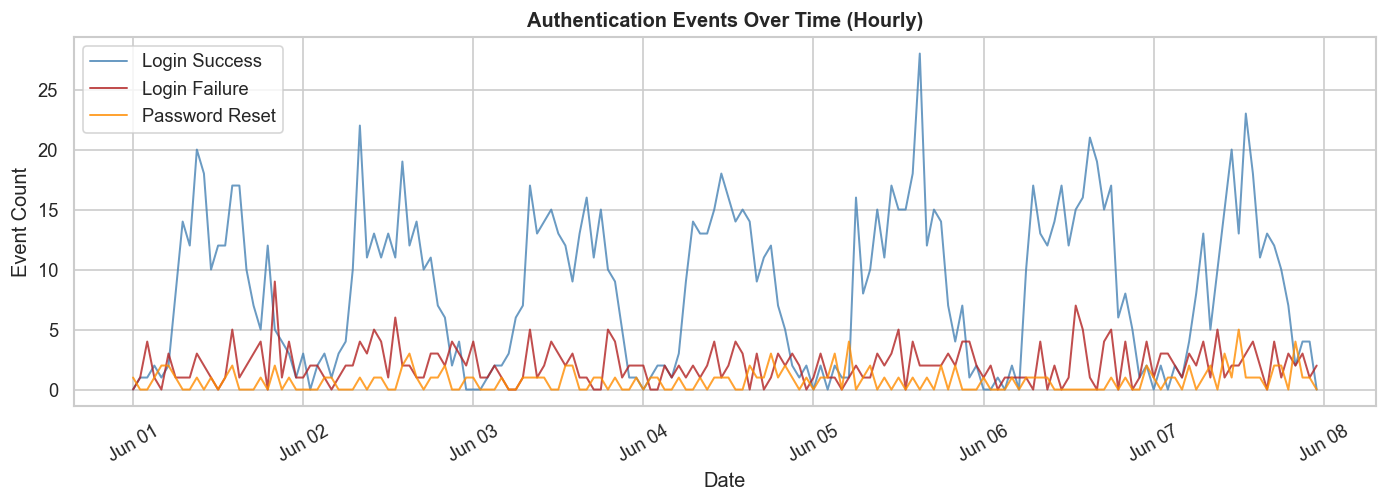

  💾 Saved → outputs\figures\01_login_timeline.png


'outputs\\figures\\01_login_timeline.png'

In [11]:
# ── Figure 1: Login Events Over Time ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 4))

daily = df.set_index('timestamp').resample('h')['event_type'].value_counts().unstack(fill_value=0)

for col, color in zip(['login_success', 'login_failure', 'password_reset'],
                       ['steelblue', 'firebrick', 'darkorange']):
    if col in daily.columns:
        ax.plot(daily.index, daily[col], label=col.replace('_', ' ').title(),
                color=color, linewidth=1.2, alpha=0.8)

ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.xaxis.set_major_locator(mdates.DayLocator())
plt.xticks(rotation=30)
ax.set_title('Authentication Events Over Time (Hourly)', fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Event Count')
ax.legend()
save_figure('01_login_timeline')

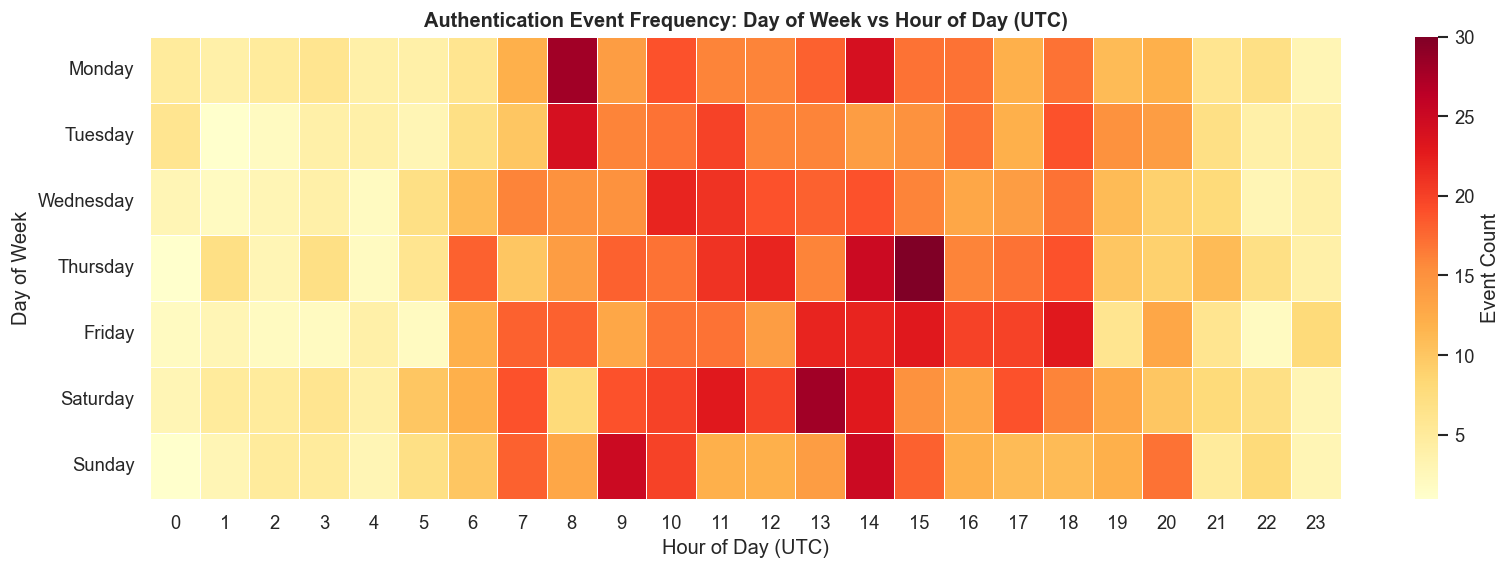

  💾 Saved → outputs\figures\02_hourly_heatmap.png


'outputs\\figures\\02_hourly_heatmap.png'

In [12]:
# ── Figure 2: Hourly Login Heatmap (Day-of-Week × Hour-of-Day) ───────────────
df_temp = df.copy()
df_temp['hour']       = df_temp['timestamp'].dt.hour
df_temp['day_of_week'] = df_temp['timestamp'].dt.day_name()

DOW_ORDER = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heatmap_data = (
    df_temp.groupby(['day_of_week', 'hour'])
    .size()
    .unstack(fill_value=0)
    .reindex(DOW_ORDER)
)

fig, ax = plt.subplots(figsize=(16, 5))
sns.heatmap(heatmap_data, cmap='YlOrRd', ax=ax, linewidths=0.3,
            cbar_kws={'label': 'Event Count'})
ax.set_title('Authentication Event Frequency: Day of Week vs Hour of Day (UTC)',
             fontweight='bold')
ax.set_xlabel('Hour of Day (UTC)')
ax.set_ylabel('Day of Week')
save_figure('02_hourly_heatmap')

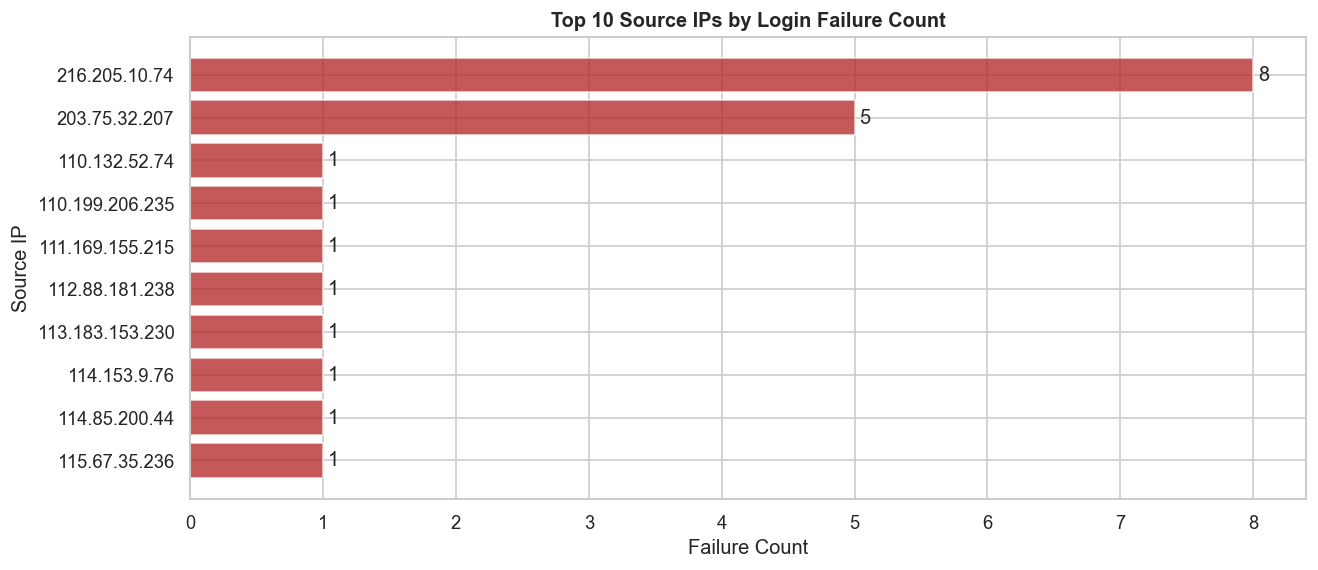

  💾 Saved → outputs\figures\03_top_fail_ips.png


'outputs\\figures\\03_top_fail_ips.png'

In [13]:
# ── Figure 3: Top 10 Source IPs by Failure Count ─────────────────────────────
top_ips = (
    df[df['event_type'] == 'login_failure']
    .groupby('source_ip')
    .size()
    .sort_values(ascending=False)
    .head(10)
)

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.barh(top_ips.index[::-1], top_ips.values[::-1], color='firebrick', alpha=0.75)
ax.bar_label(bars, padding=3)
ax.set_title('Top 10 Source IPs by Login Failure Count', fontweight='bold')
ax.set_xlabel('Failure Count')
ax.set_ylabel('Source IP')
save_figure('03_top_fail_ips')

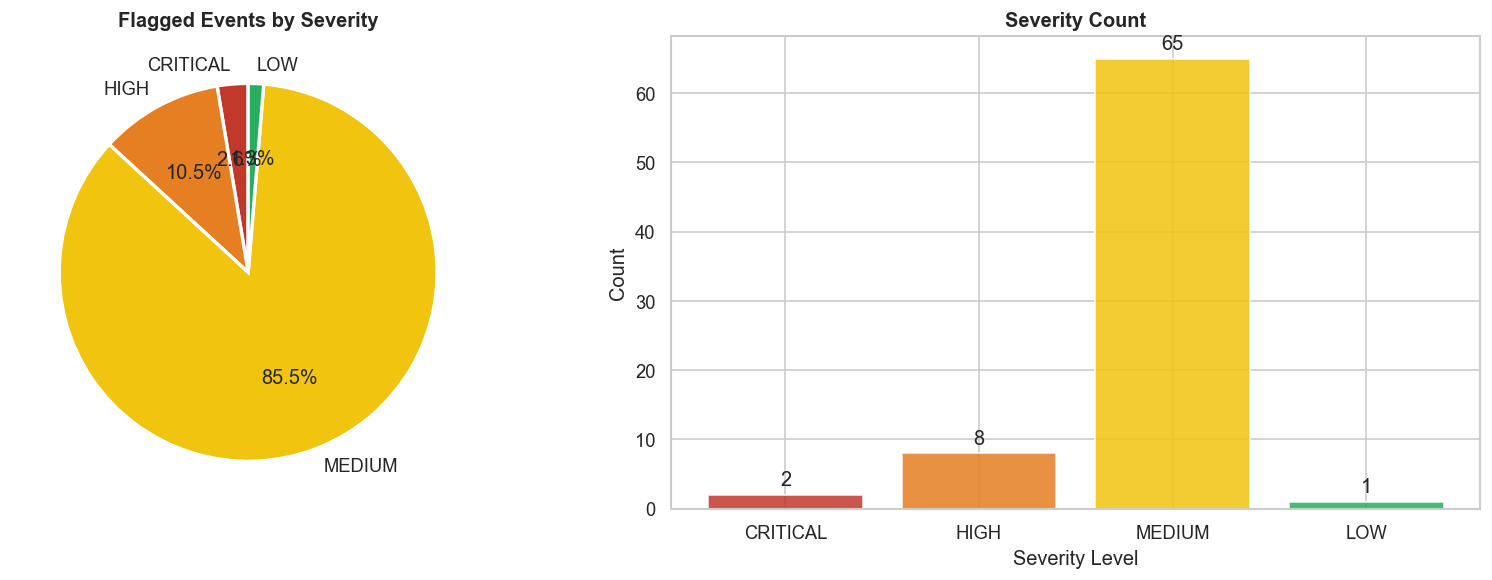

  💾 Saved → outputs\figures\04_severity_distribution.png


In [14]:
# ── Figure 4: Flagged Events by Severity ─────────────────────────────────────
if total_flagged > 0:
    sev_order = ['CRITICAL', 'HIGH', 'MEDIUM', 'LOW']
    sev_colors = {'CRITICAL': '#C0392B', 'HIGH': '#E67E22', 'MEDIUM': '#F1C40F', 'LOW': '#27AE60'}
    sev_counts_plot = flagged_df['severity'].value_counts().reindex(sev_order).dropna()
    colors = [sev_colors[s] for s in sev_counts_plot.index]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Pie chart
    axes[0].pie(
        sev_counts_plot.values,
        labels=sev_counts_plot.index,
        colors=colors,
        autopct='%1.1f%%',
        startangle=90,
        wedgeprops={'edgecolor': 'white', 'linewidth': 2},
    )
    axes[0].set_title('Flagged Events by Severity', fontweight='bold')

    # Bar chart
    bars = axes[1].bar(sev_counts_plot.index, sev_counts_plot.values, color=colors, alpha=0.85)
    axes[1].bar_label(bars, padding=3)
    axes[1].set_title('Severity Count', fontweight='bold')
    axes[1].set_xlabel('Severity Level')
    axes[1].set_ylabel('Count')

    plt.tight_layout()
    save_figure('04_severity_distribution')
else:
    print('No flagged events — skipping severity chart.')

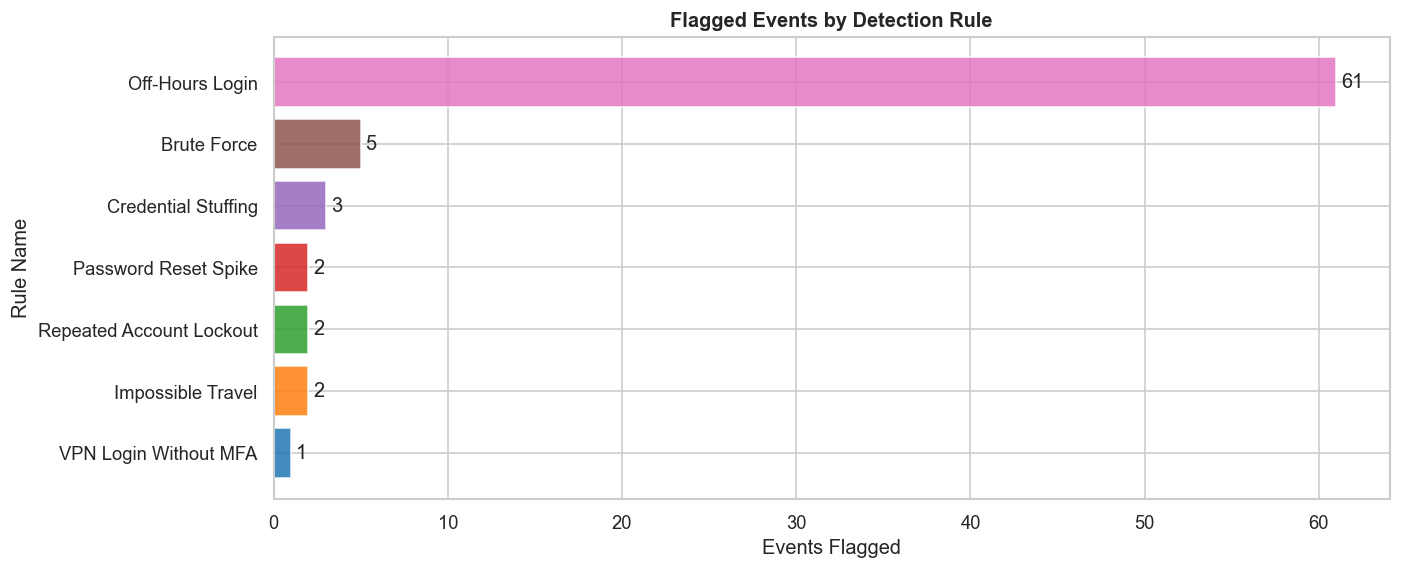

  💾 Saved → outputs\figures\05_flags_by_rule.png


In [15]:
# ── Figure 5: Flagged Events by Rule ─────────────────────────────────────────
if total_flagged > 0:
    rule_counts = flagged_df['rule_name'].value_counts().sort_values()

    fig, ax = plt.subplots(figsize=(12, 5))
    colors = plt.cm.tab10(range(len(rule_counts)))
    bars = ax.barh(rule_counts.index, rule_counts.values, color=colors, alpha=0.85)
    ax.bar_label(bars, padding=3)
    ax.set_title('Flagged Events by Detection Rule', fontweight='bold')
    ax.set_xlabel('Events Flagged')
    ax.set_ylabel('Rule Name')
    save_figure('05_flags_by_rule')
else:
    print('No flagged events — skipping rule chart.')

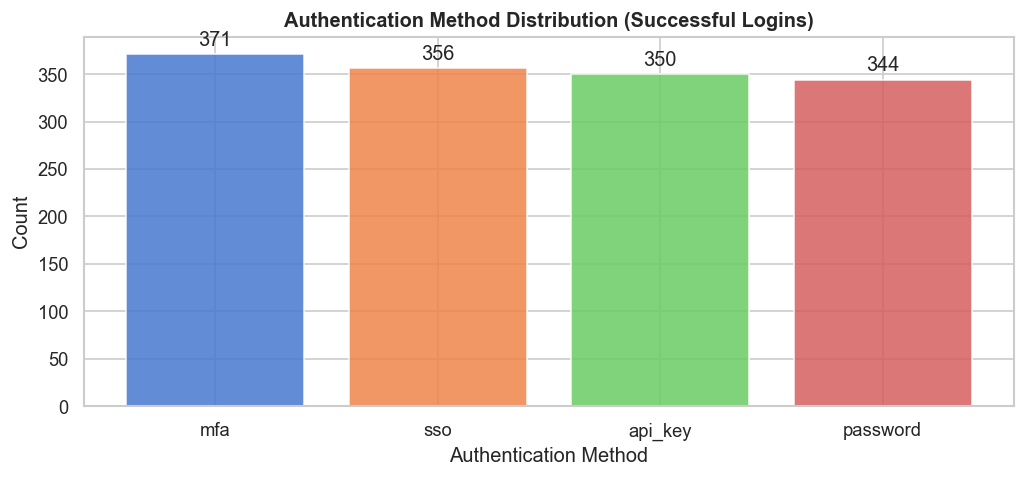

  💾 Saved → outputs\figures\06_auth_methods.png

💾 Total figures saved: 6


In [16]:
# ── Figure 6: Authentication Method Distribution ──────────────────────────────
auth_success = df[df['event_type'] == 'login_success']['auth_method'].value_counts()

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(auth_success.index, auth_success.values,
               color=sns.color_palette('muted', len(auth_success)), alpha=0.85)
ax.bar_label(bars, padding=3)
ax.set_title('Authentication Method Distribution (Successful Logins)', fontweight='bold')
ax.set_xlabel('Authentication Method')
ax.set_ylabel('Count')
save_figure('06_auth_methods')

print(f'\n💾 Total figures saved: {len(_saved_figures)}')

---
## Section 7 — Export Flagged Events
Save the flagged events to `data/processed/flagged_events.csv` and `outputs/reports/flagged_events.csv`.

In [17]:
if total_flagged > 0:
    # Save to processed/
    flagged_path_proc = DATA_PROCESSED / 'flagged_events.csv'
    flagged_df.to_csv(flagged_path_proc, index=False)
    print(f'✅ Saved flagged events → {flagged_path_proc}  ({total_flagged:,} rows)')

    # Save to outputs/reports/ as well
    flagged_path_out = REPORTS_DIR / 'flagged_events.csv'
    flagged_df.to_csv(flagged_path_out, index=False)
    print(f'✅ Saved flagged events → {flagged_path_out}  ({total_flagged:,} rows)')

    # Show a final formatted summary table
    summary_display = (
        flagged_df.groupby(['rule_id', 'rule_name', 'severity'])
        .agg(
            events=('event_id', 'count'),
            unique_ips=('source_ip', 'nunique'),
            unique_users=('username', 'nunique')
        )
        .reset_index()
        .sort_values('rule_id')
    )
    print()
    print(tabulate(summary_display, headers='keys', tablefmt='pretty', showindex=False))
else:
    print('No flagged events to export.')

✅ Saved flagged events → data\processed\flagged_events.csv  (76 rows)
✅ Saved flagged events → outputs\reports\flagged_events.csv  (76 rows)

+---------+--------------------------+----------+--------+------------+--------------+
| rule_id |        rule_name         | severity | events | unique_ips | unique_users |
+---------+--------------------------+----------+--------+------------+--------------+
|  R-01   |       Brute Force        |   HIGH   |   5    |     2      |      2       |
|  R-02   |   Credential Stuffing    |   HIGH   |   3    |     1      |      3       |
|  R-03   |     Off-Hours Login      |  MEDIUM  |   61   |     61     |      61      |
|  R-04   |    Impossible Travel     | CRITICAL |   2    |     2      |      1       |
|  R-05   | Repeated Account Lockout |  MEDIUM  |   2    |     2      |      1       |
|  R-06   |  VPN Login Without MFA   |   LOW    |   1    |     1      |      1       |
|  R-07   |   Password Reset Spike   |  MEDIUM  |   2    |     1      |    

---
## Section 8 — Generate Project Report (.docx)
Auto-generate a fully formatted Word document with all findings, tables, charts, and recommendations.

In [18]:
REPORT_PATH = f'{AUTHOR_NAME}_ProjectReport.docx'

print(f'📄 Generating project report: {REPORT_PATH}')
print(f'   Author    : {AUTHOR_NAME}')
print(f'   Figures   : {len(_saved_figures)}')
print(f'   Flagged   : {total_flagged:,} events')

report_path = build_report(
    flagged_df   = flagged_df if total_flagged > 0 else None,
    raw_df       = df,
    figure_paths = _saved_figures,
    author_name  = AUTHOR_NAME,
    output_path  = REPORT_PATH,
)

print(f'\n✅ Report ready → {report_path}')

📄 Generating project report: Aaliya_ProjectReport.docx
   Author    : Aaliya
   Figures   : 6
   Flagged   : 76 events


[report_builder] Report saved → Aaliya_ProjectReport.docx

✅ Report ready → Aaliya_ProjectReport.docx


---
## Section 9 — Conclusions

### What was accomplished

1. **Dataset** — A reproducible synthetic authentication log was generated, containing ~2,000 events with deliberately injected attack patterns.
2. **EDA** — Explored event type distribution, failure reasons, source countries, VPN usage, and top attacker IPs.
3. **Detection** — Seven deterministic, explainable rules were applied: Brute Force, Credential Stuffing, Off-Hours Login, Impossible Travel, Repeated Account Lockout, VPN Without MFA, and Password Reset Spike.
4. **Explainability** — Every flagged event includes a plain-English explanation traceable to the triggering rule and its specific thresholds.
5. **Visualizations** — Six charts were produced and saved to `outputs/figures/`.
6. **Reporting** — Flagged events were exported to CSV and a structured `.docx` report was generated automatically.

### Scope & Limitations

- Detection is limited to structured authentication logs. Network, endpoint, and application-layer attacks are out of scope.
- Rule thresholds are illustrative; production use requires tuning to environment-specific baselines.
- This project does not claim to detect all cyberattacks.
- No automated remediation is performed — all outputs are advisory only.

### Possible Extensions

- **Anomaly detection:** Add z-score or IQR-based per-user baselines for login frequency
- **SIEM integration:** Forward flagged events to a syslog or SIEM via UDP/TCP
- **Real log ingestion:** Adapter for Linux `/var/log/auth.log` or Windows Event Log XML
- **Geolocation map:** Plot flagged IPs on a choropleth map using GeoPandas
- **Dashboard:** Wrap visualizations in a Streamlit or Panel dashboard

In [19]:
# ── Final deliverables checklist ──────────────────────────────────────────────
import os

deliverables = [
    (f'{AUTHOR_NAME}_ThreatLens.ipynb',            'Main notebook'),
    (f'{AUTHOR_NAME}_ProjectReport.docx',           'Project report'),
    ('requirements.txt',                             'Dependencies'),
    ('README.md',                                    'Documentation'),
    ('data/raw/auth_logs.csv',                       'Raw dataset'),
    ('data/processed/flagged_events.csv',            'Processed flagged events'),
    ('outputs/reports/flagged_events.csv',           'Report flagged events'),
]

print('── Deliverables Checklist ──────────────────────────────────')
all_ok = True
for path, label in deliverables:
    exists = os.path.exists(path)
    status = '✅' if exists else '❌'
    size = f'({os.path.getsize(path):,} bytes)' if exists else '(MISSING)'
    print(f'  {status}  {label:<35} {size}')
    if not exists:
        all_ok = False

print()
figures_found = list(FIGURES_DIR.glob('*.png'))
print(f'  📊  Figures in outputs/figures/       ({len(figures_found)} PNG files)')
print()
if all_ok:
    print('✅ All deliverables present. Analysis complete!')
else:
    print('⚠️  Some deliverables are missing — re-run cells above.')

── Deliverables Checklist ──────────────────────────────────
  ✅  Main notebook                       (508,057 bytes)
  ✅  Project report                      (441,437 bytes)
  ✅  Dependencies                        (267 bytes)
  ✅  Documentation                       (5,737 bytes)
  ✅  Raw dataset                         (362,128 bytes)
  ✅  Processed flagged events            (23,542 bytes)
  ✅  Report flagged events               (23,542 bytes)

  📊  Figures in outputs/figures/       (6 PNG files)

✅ All deliverables present. Analysis complete!
